# Assessments

In [1]:
# import relevant libraries to run the notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

## 1. Exploring Petal length

**Load the Iris dataset** 

The Irish dataset etc....

In [2]:
# load the iris dataset 
iris = datasets.load_iris()


In [3]:
# read it as dataframe with Pandas
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
# preview df
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [4]:
# create a new variable for the petal length column
iris_petal_length = iris_df['petal length (cm)']
iris_petal_length.head()

0    1.4
1    1.4
2    1.3
3    1.5
4    1.4
Name: petal length (cm), dtype: float64

### 1.1 Histogram of Petal Length

Petal length is plotted in a histogram. Since the data is continuous and not discrete, that makes more sense than a bar chart. The histogram allows to visualize continuous data as intervals, which means is makes it easier to identify trends. 

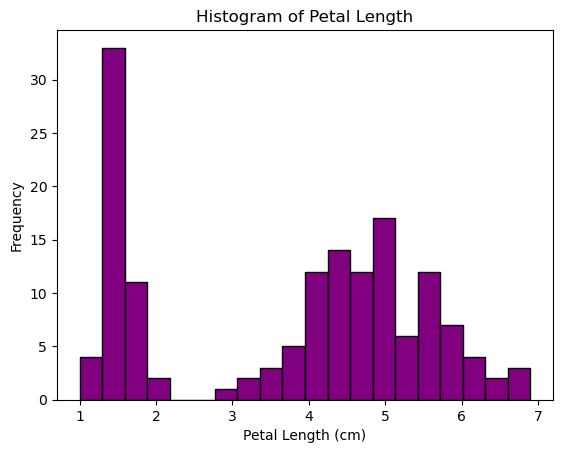

In [5]:
# plot data in a histogram 
plt.hist(iris_petal_length, bins=20, color='purple', edgecolor='black')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Frequency')
plt.title('Histogram of Petal Length')
plt.show()

The histogram highlights a pattern in the data. There is a high peak between 1-2cm, and then a blank space and another peak between 3-7cm. 

The overall data does not show a individual trend of normal distribution. However, it seems like two normal distributions could be identified. This is possibly due to differences among the 3 Iris species. 

### 1.2 Normal Distribution

Although the histogram does not show a pattern of normal distribution, the normal distribution line is calculated using the mean and standard deviation of the data. 

In [6]:
# calculate mean and standard deviation 
pl_mean = np.mean(iris_petal_length)
pl_std = np.std(iris_petal_length)
pl_mean, pl_std

(3.7580000000000005, 1.7594040657753032)

**Normal Distribution**, or **Gaussian Distribution**, is  is a type of continuous probability distribution for a real-valued random variable. 

The formula for probability density of normal distribution is defined as: 

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}} e^{-\frac{(x - \mu)^2}{2\sigma^2}}$$

where $\mu$ is the mean of the data interval and $\sigma$ its standard deviation. Using this formula, it's possible to calculate the values of a normal distribution curve extending from -∞ to +∞.

Since it would not be possible to represent the infinity of data points, a range is selected that covers ~99% of the data by adding and subtracting to the mean of Petal length its standard deviation, multiplied by 3. 


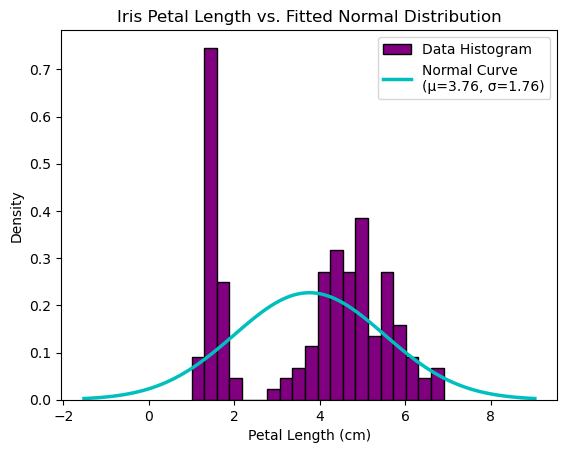

In [20]:
# Create an array of x-values using the mean and standard deviation to cover a range of values
xmin = pl_mean - 3 * pl_std
xmax = pl_mean + 3 * pl_std
x = np.linspace(xmin, xmax, 100)

# Compute the normal distribution curve values
p = stats.norm.pdf(x, pl_mean, pl_std)

# Plot the data. The parameter Density=True so the scale matches the normal curve
plt.hist(iris_petal_length, bins=20, density=True, color='purple', edgecolor='black', label='Data Histogram')

# Superimpose the normal curve line
plt.plot(x, p, 'c-', linewidth=2.5, label=f'Normal Curve\n(μ={pl_mean:.2f}, σ={pl_std:.2f})')

# 7. Add layout metadata and labels
plt.title('Iris Petal Length vs. Fitted Normal Distribution')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Density') # Y-axis represents relative likelihood, not counts
plt.legend()
plt.show()


**Probability of Normal Distribution** 

Normal distribution generated from the whole array of Petal length does not seem to fit the data precisely. 

To verify this hypothesis, the probability of the data fitting normal distribution is represented using [Scipy.stats.probplot](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.probplot.html). This function allows to 
visualize in a plot actual values and theoretical values (based on a distribution theory), and fit a line that would show perfect match between values and distribution. 

In this case, the values don't perfectly match the distribution line, in particular for the first interval of data. The second interval, however, is much closer to the Normal distribution line. Which aligns wtih what was observed about the histogram. 


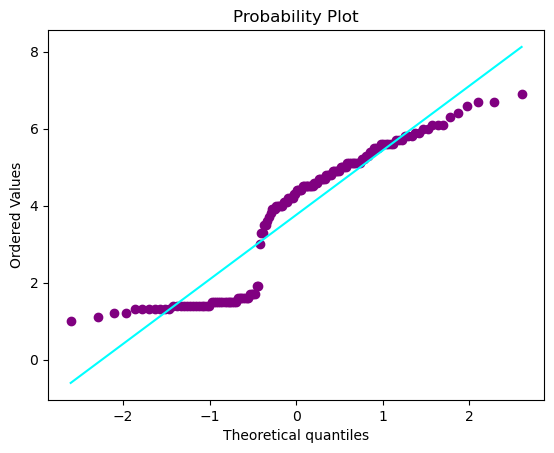

In [ ]:
# Create a Q-Q plot to assess normality https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.probplot.html
prob1 = stats.probplot(iris_petal_length, dist="norm", plot=plt)

# uniform colors to the histogram and the reference line
plt.gca().get_lines()[0].set_color('purple')  # Dots
plt.gca().get_lines()[1].set_color('cyan')    # Reference line

plt.show()

Then, the **[Shapiro-Wilk test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html#shapiro)** is used to test the null hypothesis that given data was draw from a normal distribution. 

The function returns two values: 
- Statistics: an interval of 0-1 which measures the correlation between real data and ideal data in a normal distribution.  
- P-value: The probability of the data being drawn from a normal distribution, where 0 is the Null Hypothesis (the data is not a normal distribution) and 1 is the Alternative Hypothesis. [Scipy.stats.shapiro](https://share.google/aimode/AGUsctcWSDn4BhaVj), [Shapiro-Wilk test](https://en.wikipedia.org/wiki/Shapiro%E2%80%93Wilk_test). 

In [9]:
# Perform the Shapiro-Wilk test for normality. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html#shapiro
prob2 = stats.shapiro(iris_petal_length)

prob2.statistic, prob2.pvalue

(0.8762680554631075, 7.412263135173186e-10)

### 1.3 Investigate Iris species individually

To verify the hypothesis the overll data for Petal Lenght is now drawn from a normal distribution, but the data for each species might, data about each species is split and plotted in 3 histograms. 

In [15]:
# add targets to dataframe
iris_df['target'] = iris.target

# preview data
iris_df.head(3)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0


In [16]:
# create arrays for each Irish species
setosa = iris_df[iris_df['target'] == 0]['petal length (cm)']
versicolor = iris_df[iris_df['target'] == 1]['petal length (cm)']
virginica = iris_df[iris_df['target'] == 2]['petal length (cm)']

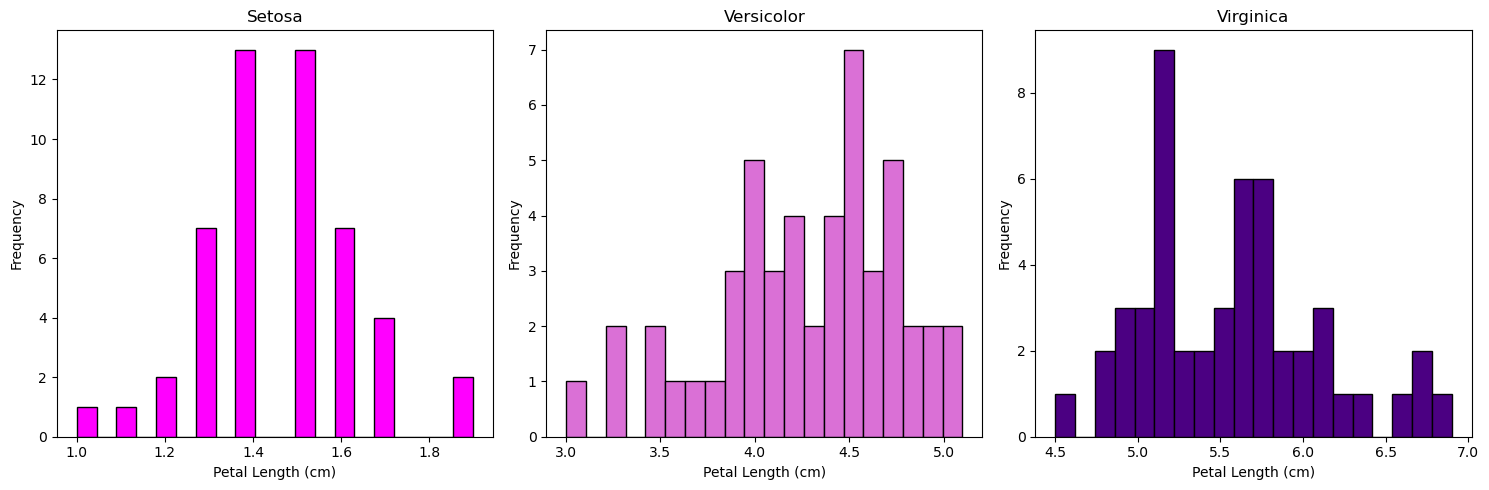

In [29]:
# plot 3 histograms for each species
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Setosa
axes[0].hist(setosa, bins=20, color='magenta', edgecolor='black')
axes[0].set_title('Setosa')
axes[0].set_xlabel('Petal Length (cm)')
axes[0].set_ylabel('Frequency')

# Versicolor
axes[1].hist(versicolor, bins=20, color='orchid', edgecolor='black')
axes[1].set_title('Versicolor')
axes[1].set_xlabel('Petal Length (cm)')
axes[1].set_ylabel('Frequency')

# Virginica
axes[2].hist(virginica, bins=20, color='indigo', edgecolor='black')
axes[2].set_title('Virginica')
axes[2].set_xlabel('Petal Length (cm)')
axes[2].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [30]:
# calculate mean and normal distribution for each species
setosa_mean = np.mean(setosa)
setosa_std = np.std(setosa)

virginica_mean = np.mean(virginica)
virginica_std = np.std(virginica)

versicolor_mean = np.mean(versicolor)
versicolor_std = np.std(versicolor)

In [31]:
# calculate normal distribution for each variety
# Setosa
setosa_x = np.linspace(max(0, setosa_mean - 3*setosa_std),
                       setosa_mean + 3*setosa_std, 100)
setosa_p = stats.norm.pdf(setosa_x, setosa_mean, setosa_std)

# Versicolor
versicolor_x = np.linspace(max(0, versicolor_mean - 3*versicolor_std),
                           versicolor_mean + 3*versicolor_std, 100)
versicolor_p = stats.norm.pdf(versicolor_x, versicolor_mean, versicolor_std)

# Virginica
virginica_x = np.linspace(max(0, virginica_mean - 3*virginica_std),
                          virginica_mean + 3*virginica_std, 100)
virginica_p = stats.norm.pdf(virginica_x, virginica_mean, virginica_std)

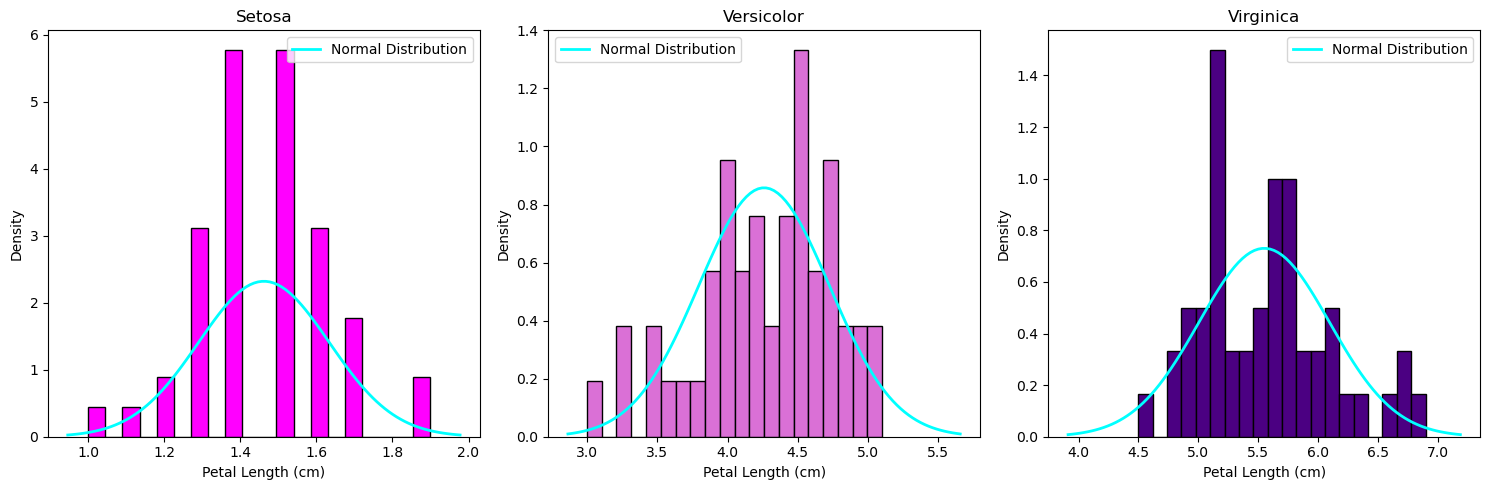

In [32]:
# Plot 3 histograms for each species
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Setosa
axes[0].hist(setosa, bins=20, density=True, color='magenta', edgecolor='black')
axes[0].plot(setosa_x, setosa_p, color='cyan', linewidth=2, label='Normal Distribution')
axes[0].set_title('Setosa')
axes[0].set_xlabel('Petal Length (cm)')
axes[0].set_ylabel('Density')
axes[0].legend()

# Versicolor
axes[1].hist(versicolor, bins=20, density=True, color='orchid', edgecolor='black')
axes[1].plot(versicolor_x, versicolor_p, color='cyan', linewidth=2, label='Normal Distribution')
axes[1].set_title('Versicolor')
axes[1].set_xlabel('Petal Length (cm)')
axes[1].set_ylabel('Density')
axes[1].legend()

# Virginica
axes[2].hist(virginica, bins=20, density=True, color='indigo', edgecolor='black')
axes[2].plot(virginica_x, virginica_p, color='cyan', linewidth=2, label='Normal Distribution')
axes[2].set_title('Virginica')
axes[2].set_xlabel('Petal Length (cm)')
axes[2].set_ylabel('Density')
axes[2].legend()

plt.tight_layout()
plt.show()

- Setosa seems to show a normal distribution, but with a different curve. It would be interesting to experiment with higher standard deviation. 
- the other 2 don't seem to fit normal distribution. 

# End